# [4-b] 전이학습: ResNet18로 태권도 자세 분류

AI개론 14차시처럼 **ImageNet(사진 120만 장, 1000종류)으로 미리 학습된 ResNet18**을 가져와서,
마지막 층(`fc`)만 우리 클래스 3개로 바꿔서 학습합니다.

데이터가 1천 장 정도로 적을 때, 처음부터 학습하는 것보다 훨씬 잘 되는 경우가 많아요.
이미 "선, 모양, 사람 형태"를 알아보는 법을 배운 모델이라서요.

| 버전 | 학습하는 부분 | 학습률 |
|---|---|---|
| A 동결 (freeze) | 마지막 `fc`만 (나머지 가중치는 고정) | fc 0.001 |
| B 미세조정 (fine-tune) | 전체 | 백본 0.0001 / fc 0.001 (차등 학습률) |

- 입력: 224 × 224 (ResNet이 학습한 크기), ImageNet 평균·표준편차로 정규화
- train에만 좌우 뒤집기 증강
- 처음 실행할 때 ResNet18 가중치(약 45MB)를 인터넷에서 자동으로 받아요

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [2]:
from torchvision import models

# ImageNet 사진들의 RGB 평균, 표준편차 (사전학습 모델은 이 값으로 정규화해야 함)
MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

train_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(),     # 학습 때만 좌우 뒤집기
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
val_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# 같은 폴더를 transform만 다르게 두 번 읽고, A040으로 나눔 (지금까지와 같은 분할)
train_ds = datasets.ImageFolder("tk_crops", transform=train_tf)
val_ds = datasets.ImageFolder("tk_crops", transform=val_tf)
classes = train_ds.classes

VAL_PERSON = "A040"
train_idx = [i for i, (p, _) in enumerate(train_ds.samples) if VAL_PERSON not in os.path.basename(p)]
val_idx = [i for i, (p, _) in enumerate(train_ds.samples) if VAL_PERSON in os.path.basename(p)]

train_loader = DataLoader(Subset(train_ds, train_idx), batch_size=32, shuffle=True)
val_loader = DataLoader(Subset(val_ds, val_idx), batch_size=32, shuffle=False)
print("클래스:", classes, "/ train:", len(train_idx), " val:", len(val_idx))

클래스: ['1_start', '2_middle', '3_end'] / train: 933  val: 264


In [3]:
criterion = nn.CrossEntropyLoss()

def train_model(model, optimizer, train_loader, val_loader, save_path, max_epochs=50, patience=5):
    """학습 + Early Stopping
    - val loss가 좋아질 때마다 모델을 파일(save_path)로 저장
    - patience번 연속으로 안 좋아지면 학습을 멈춤
    - 끝나면 제일 좋았던 모델을 다시 불러옴
    """
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_loss = float("inf")    # 지금까지 제일 낮은 val loss (처음엔 무한대)
    wait = 0                    # 몇 번 연속으로 안 좋아졌는지

    for epoch in range(max_epochs):
        # ----- 학습 -----
        model.train()
        total_loss, correct, total = 0, 0, 0
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)
        train_loss, train_acc = total_loss / total, correct / total

        # ----- 검증 -----
        model.eval()
        total_loss, correct, total = 0, 0, 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                total_loss += criterion(outputs, labels).item() * labels.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)
        val_loss, val_acc = total_loss / total, correct / total

        history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
        msg = f"Epoch {epoch + 1:2d} | train loss {train_loss:.4f} acc {train_acc:.4f} | val loss {val_loss:.4f} acc {val_acc:.4f}"

        # ----- Early Stopping -----
        if val_loss < best_loss:
            best_loss = val_loss
            wait = 0
            torch.save(model.state_dict(), save_path)     # 제일 좋은 모델 저장
            msg += "  ← best 저장"
        else:
            wait += 1
            msg += f"  (좋아지지 않음 {wait}/{patience})"
        print(msg)
        if wait >= patience:
            print(f"→ {patience}번 연속 val loss가 좋아지지 않아서 {epoch + 1} epoch에서 멈춤")
            break

    model.load_state_dict(torch.load(save_path))          # 제일 좋았던 모델로 되돌리기
    return history

In [4]:
def evaluate(model, val_loader, n_classes=3):
    """정확도와 혼동행렬 (행 = 정답, 열 = 예측)"""
    model.eval()
    cm = np.zeros((n_classes, n_classes), dtype=int)
    with torch.no_grad():
        for images, labels in val_loader:
            preds = model(images.to(device)).argmax(1).cpu()
            for t, p in zip(labels, preds):
                cm[t, p] += 1
    acc = np.trace(cm) / cm.sum()       # 대각선 합 / 전체
    return acc, cm

def plot_cm(cm, classes, title):
    plt.imshow(cm, cmap="Blues")
    plt.xticks(range(len(classes)), classes); plt.yticks(range(len(classes)), classes)
    plt.xlabel("예측"); plt.ylabel("정답"); plt.title(title)
    for i in range(len(classes)):
        for j in range(len(classes)):
            plt.text(j, i, cm[i, j], ha="center", va="center")

## ResNet18 불러와서 마지막 층 바꾸기

In [5]:
def build_resnet(strategy):
    model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)   # 사전학습 가중치

    if strategy == "freeze":
        for param in model.parameters():
            param.requires_grad = False        # 전부 동결 (학습 안 함)

    # 마지막 층 교체: 1000종류 → 3종류 (새로 만든 층은 requires_grad=True라서 학습됨)
    in_features = model.fc.in_features         # 512
    model.fc = nn.Linear(in_features, 3)
    return model.to(device)

m = build_resnet("freeze")
print(m.fc)
total = sum(p.numel() for p in m.parameters())
trainable = sum(p.numel() for p in m.parameters() if p.requires_grad)
print(f"전체 파라미터 {total:,} 중 학습하는 파라미터 {trainable:,}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\<user>/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 47.1MB/s]


Linear(in_features=512, out_features=3, bias=True)
전체 파라미터 11,178,051 중 학습하는 파라미터 1,539


## A. 동결 (fc만 학습)

In [6]:
results, models_, val_loaders = {}, {}, {}
torch.manual_seed(42)
model_a = build_resnet("freeze")
opt_a = optim.Adam(model_a.fc.parameters(), lr=0.001)     # fc 파라미터만 optimizer에 넣음
results["A 동결"] = train_model(model_a, opt_a, train_loader, val_loader, "best_resnet_freeze.pth", max_epochs=30)
models_["A 동결"], val_loaders["A 동결"] = model_a, val_loader

Epoch  1 | train loss 1.0578 acc 0.4341 | val loss 1.0131 acc 0.4545  ← best 저장
Epoch  2 | train loss 0.9071 acc 0.5809 | val loss 0.9408 acc 0.5265  ← best 저장
Epoch  3 | train loss 0.8530 acc 0.6281 | val loss 0.9090 acc 0.5758  ← best 저장
Epoch  4 | train loss 0.7918 acc 0.6688 | val loss 0.8171 acc 0.6477  ← best 저장
Epoch  5 | train loss 0.7373 acc 0.6827 | val loss 0.7771 acc 0.6818  ← best 저장
Epoch  6 | train loss 0.6837 acc 0.7481 | val loss 0.7601 acc 0.6629  ← best 저장
Epoch  7 | train loss 0.6451 acc 0.7599 | val loss 0.7633 acc 0.6856  (좋아지지 않음 1/5)
Epoch  8 | train loss 0.6491 acc 0.7385 | val loss 0.7414 acc 0.6818  ← best 저장
Epoch  9 | train loss 0.6270 acc 0.7621 | val loss 0.7648 acc 0.6818  (좋아지지 않음 1/5)
Epoch 10 | train loss 0.6068 acc 0.7728 | val loss 0.7075 acc 0.7008  ← best 저장
Epoch 11 | train loss 0.6081 acc 0.7535 | val loss 0.6957 acc 0.7159  ← best 저장
Epoch 12 | train loss 0.5895 acc 0.7685 | val loss 0.7189 acc 0.6856  (좋아지지 않음 1/5)
Epoch 13 | train loss 0.5577

## B. 미세조정 (전체 학습, 차등 학습률)

In [7]:
torch.manual_seed(42)
model_b = build_resnet("finetune")

# 백본은 이미 잘 배워 있으니 조금만(0.0001), 새 fc는 많이(0.001) 바꿈
backbone_params = [p for name, p in model_b.named_parameters() if not name.startswith("fc")]
opt_b = optim.Adam([
    {"params": backbone_params, "lr": 0.0001},
    {"params": model_b.fc.parameters(), "lr": 0.001},
])
results["B 미세조정"] = train_model(model_b, opt_b, train_loader, val_loader, "best_resnet_finetune.pth", max_epochs=30)
models_["B 미세조정"], val_loaders["B 미세조정"] = model_b, val_loader

Epoch  1 | train loss 0.5576 acc 0.7481 | val loss 0.3658 acc 0.8485  ← best 저장
Epoch  2 | train loss 0.1280 acc 0.9539 | val loss 0.3501 acc 0.8295  ← best 저장
Epoch  3 | train loss 0.0846 acc 0.9753 | val loss 0.2910 acc 0.8636  ← best 저장
Epoch  4 | train loss 0.0520 acc 0.9818 | val loss 0.7306 acc 0.7462  (좋아지지 않음 1/5)
Epoch  5 | train loss 0.0365 acc 0.9914 | val loss 0.4807 acc 0.8333  (좋아지지 않음 2/5)
Epoch  6 | train loss 0.0265 acc 0.9936 | val loss 0.1294 acc 0.9545  ← best 저장
Epoch  7 | train loss 0.0182 acc 0.9946 | val loss 0.2089 acc 0.9280  (좋아지지 않음 1/5)
Epoch  8 | train loss 0.0410 acc 0.9829 | val loss 0.1599 acc 0.9470  (좋아지지 않음 2/5)
Epoch  9 | train loss 0.0782 acc 0.9753 | val loss 0.4023 acc 0.8295  (좋아지지 않음 3/5)
Epoch 10 | train loss 0.0342 acc 0.9882 | val loss 0.2546 acc 0.8977  (좋아지지 않음 4/5)
Epoch 11 | train loss 0.0518 acc 0.9818 | val loss 0.3049 acc 0.8826  (좋아지지 않음 5/5)
→ 5번 연속 val loss가 좋아지지 않아서 11 epoch에서 멈춤


## 비교

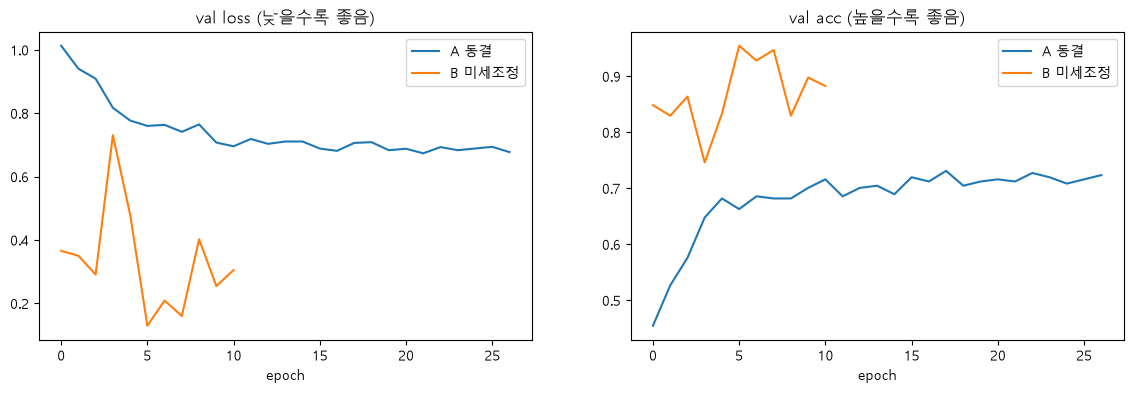

In [8]:
plt.figure(figsize=(14, 4))
plt.subplot(1, 2, 1)
for name, h in results.items():
    plt.plot(h["val_loss"], label=name)
plt.title("val loss (낮을수록 좋음)"); plt.xlabel("epoch"); plt.legend()
plt.subplot(1, 2, 2)
for name, h in results.items():
    plt.plot(h["val_acc"], label=name)
plt.title("val acc (높을수록 좋음)"); plt.xlabel("epoch"); plt.legend()
plt.show()

버전                 | 멈춘 epoch | best epoch | train acc | val acc | 차이(과적합)
A 동결               |         27 |         22 | 0.8092    | 0.7121  | +0.0971
B 미세조정             |         11 |          6 | 0.9936    | 0.9545  | +0.0390


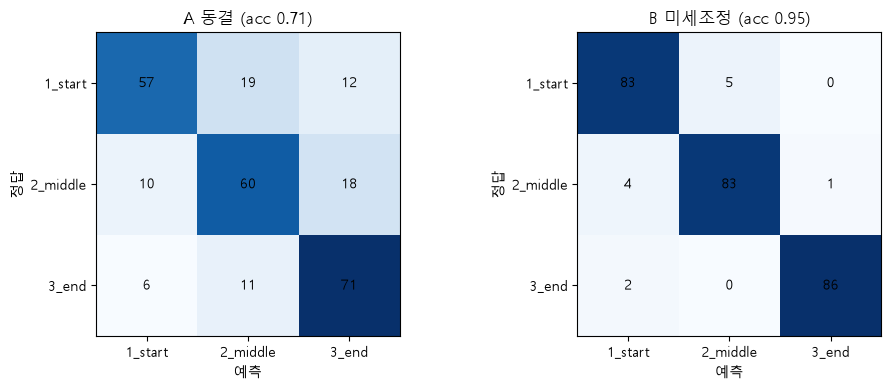

In [9]:
# 버전별 결과 정리 (best 저장 시점 = val loss가 제일 낮았던 epoch)
print(f"{'버전':18s} | 멈춘 epoch | best epoch | train acc | val acc | 차이(과적합)")
plt.figure(figsize=(5 * len(models_), 4))
for k, (name, m) in enumerate(models_.items()):
    h = results[name]
    best = int(np.argmin(h["val_loss"]))
    acc, cm = evaluate(m, val_loaders[name])
    gap = h["train_acc"][best] - acc
    print(f"{name:18s} | {len(h['val_loss']):10d} | {best + 1:10d} | {h['train_acc'][best]:.4f}    | {acc:.4f}  | {gap:+.4f}")
    plt.subplot(1, len(models_), k + 1)
    plot_cm(cm, classes, f"{name} (acc {acc:.2f})")
plt.tight_layout(); plt.show()

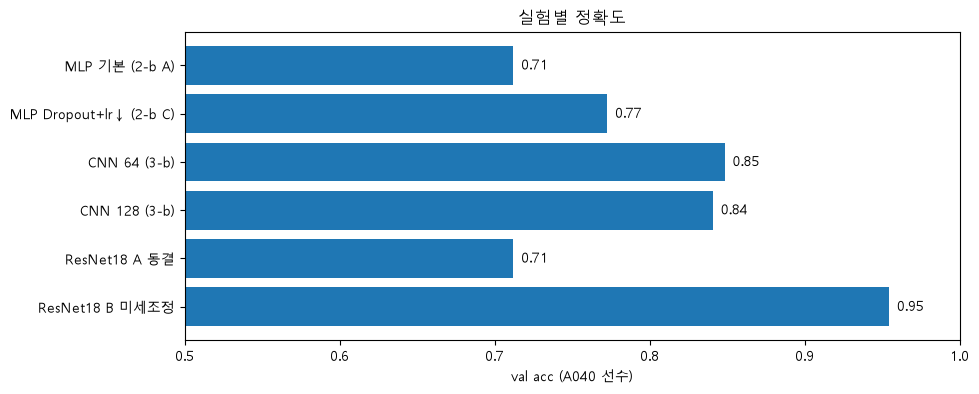

In [10]:
# 지금까지 실험 전체 비교 (앞 노트북 결과는 그때 나온 숫자를 적어둔 것)
before = {"MLP 기본 (2-b A)": 0.7121, "MLP Dropout+lr↓ (2-b C)": 0.7727,
          "CNN 64 (3-b)": 0.8485, "CNN 128 (3-b)": 0.8409}
for name, m in models_.items():
    before[f"ResNet18 {name}"] = evaluate(m, val_loader)[0]

plt.figure(figsize=(10, 4))
plt.barh(list(before.keys()), list(before.values()))
for i, v in enumerate(before.values()):
    plt.text(v + 0.005, i, f"{v:.2f}", va="center")
plt.xlim(0.5, 1.0); plt.xlabel("val acc (A040 선수)"); plt.title("실험별 정확도")
plt.gca().invert_yaxis(); plt.show()

In [11]:
# 미세조정 모델로 val 사진 8장 예측 (빨간 제목 = 틀림)
images, labels = next(iter(val_loader))
model_b.eval()
with torch.no_grad():
    probs = torch.softmax(model_b(images.to(device)), dim=1).cpu()
preds = probs.argmax(1)

mean, std = torch.tensor(MEAN).view(3, 1, 1), torch.tensor(STD).view(3, 1, 1)
plt.figure(figsize=(14, 3.5))
for i in range(8):
    img = (images[i] * std + mean).permute(1, 2, 0).clamp(0, 1)   # ImageNet 정규화 되돌리기
    plt.subplot(1, 8, i + 1); plt.imshow(img)
    color = "black" if preds[i] == labels[i] else "red"
    plt.title(f"정답 {classes[labels[i]]}\n예측 {classes[preds[i]]}\n{probs[i, preds[i]]:.0%}", fontsize=8, color=color)
    plt.axis("off")
plt.show()

## 생각해볼 것
1. 동결은 학습하는 파라미터가 1,539개뿐인데 정확도가 얼마나 나왔어? 직접 만든 CNN(55만 개)과 비교하면?
2. 미세조정에서 백본 학습률을 fc보다 10배 작게 준 이유는?
3. 시작 ↔ 중간 헷갈림(혼동행렬 왼쪽 위)이 [3-b] CNN보다 줄었어?
4. 입력을 64에서 224로 키운 효과도 섞여 있어요. 공평하게 비교하려면 어떻게 해야 할까?